# Atropelamentos em São Paulo (2022–2025): classificador de gravidade e função `risco()`

**Pré-requisitos:** notebooks 01 (bases tratadas) e 03 (banco `seguranca_viaria.db` com os grupos do DBSCAN).

**Pergunta:** dado **onde** e **quando** (e se está chovendo), qual a chance de um atropelamento ser **fatal**?
A resposta vira a função `risco(lat, lon, quando, chuva_mm)` em `src/estudo_b_risco_vida/risco.py`, que a
central (Python) e o nó ESP32 vão chamar no dia 17.

**Diferença para o notebook 02.** O 02 é **explicativo**: uma regressão logística sobre a **vítima** (idade,
sexo), para entender o que pesa na morte. Este notebook é **preditivo** e trabalha com o **sinistro**. A
`risco()` é chamada **antes** do atropelamento, sem saber quem será atropelado. Por isso **não usamos
nenhuma variável da vítima**, só o que se conhece de antemão: hora, dia, mês, chuva e características do local.

**Plano B (previsto no planejamento):** se o modelo for fraco, ou seja, com PR-AUC pouco acima da proporção
de fatais, isso é reportado como limitação e o nó usa só o índice do DBSCAN.

## 1. Configuração

In [1]:
from pathlib import Path
import sys, json, sqlite3, urllib.request, datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, confusion_matrix,
                             precision_score, recall_score)
from sklearn.inspection import permutation_importance
from sklearn.neighbors import BallTree

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

def achar_raiz(inicio: Path = Path.cwd()) -> Path:
    for p in [inicio, *inicio.parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("pasta data/raw não encontrada acima de " + str(inicio))
ROOT = achar_raiz()
RAW, PROCESSED = ROOT / "data" / "raw", ROOT / "data" / "processed"
EVID = ROOT / "docs" / "evidencias" / "estudo_b"
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
DB_PATH = PROCESSED / "seguranca_viaria.db"

sys.path.insert(0, str(ROOT / "src" / "estudo_b_risco_vida"))
import risco as rv   # variáveis montadas pelas MESMAS funções que a risco() usa em produção

SEED = 42
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#bdbcb6", "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
def salvar(fig, nome):
    fig.savefig(EVID / nome, dpi=150, bbox_inches="tight", facecolor="white")

## 2. Chuva histórica (Open-Meteo)

O Infosiga não registra chuva. Usamos a **precipitação horária** da API de arquivo do Open-Meteo (reanálise,
gratuita, sem chave), de 01/01/2022 a 31/12/2025, no horário de São Paulo. O CSV fica em
`data/raw/open_meteo_precipitacao_sp_2022_2025.csv`; se não existir, a célula abaixo baixa.

**Limitação importante:** é **um ponto só para a cidade inteira** (a API devolve a célula de grade mais
próxima de -23,55 / -46,63, no centro expandido). É chuva **regional**, não chuva da rua. Uma pancada forte
na zona sul com sol no centro aparece aqui como "sem chuva", e vice-versa.

**Como juntar com o sinistro:** no Open-Meteo, o valor marcado às 19h é a chuva **entre 18h e 19h**. Um
atropelamento às 18h30 (`hora = 18`) recebe então o valor marcado às **19h**, o intervalo que contém o
horário do atropelamento. `chovendo = chuva_mm ≥ 0,2 mm`, o mínimo que um pluviômetro registra como chuva.
Atropelamentos sem hora ficam com chuva ausente.

In [2]:
ARQ_CHUVA = RAW / "open_meteo_precipitacao_sp_2022_2025.csv"
URL_CHUVA = ("https://archive-api.open-meteo.com/v1/archive?latitude=-23.55&longitude=-46.63&start_date=2022-01-01"
             "&end_date=2025-12-31&hourly=precipitation&timezone=America%2FSao_Paulo")
if not ARQ_CHUVA.exists():
    with urllib.request.urlopen(urllib.request.Request(URL_CHUVA, headers={"User-Agent": "GS-FIAP-estudo-b/1.0"}),
                                timeout=120) as r:
        om = json.loads(r.read())
    pd.DataFrame({"hora_local": om["hourly"]["time"], "precipitacao_mm": om["hourly"]["precipitation"]}).to_csv(
        ARQ_CHUVA, index=False)
    print(f"baixado: célula de grade em {om['latitude']:.3f}, {om['longitude']:.3f} ({om['timezone']})")
chuva = pd.read_csv(ARQ_CHUVA, parse_dates=["hora_local"]).set_index("hora_local")["precipitacao_mm"]
print(f"{len(chuva):,} horas | {chuva.index.min()} → {chuva.index.max()} | ausentes: {chuva.isna().sum()} | "
      f"horas com chuva (≥ 0,2 mm): {(chuva >= rv.LIMIAR_CHUVA_MM).mean():.1%}")

35,064 horas | 2022-01-01 00:00:00 → 2025-12-31 23:00:00 | ausentes: 0 | horas com chuva (≥ 0,2 mm): 12.4%


In [3]:
atrop = pd.read_parquet(PROCESSED / "atropelamentos_sp_2022_2025.parquet")
atrop["quando"] = atrop["data_sinistro"] + pd.to_timedelta(atrop["hora"].astype("float"), unit="h")
atrop["chuva_mm"] = (atrop["quando"] + pd.Timedelta(hours=1)).map(chuva)   # intervalo que contém o sinistro
atrop.loc[atrop["hora"].isna(), "chuva_mm"] = np.nan
atrop["chovendo"] = np.where(atrop["chuva_mm"].isna(), np.nan, (atrop["chuva_mm"] >= rv.LIMIAR_CHUVA_MM).astype(float))
print(f"atropelamentos: {len(atrop):,} | com chuva preenchida: {atrop['chuva_mm'].notna().sum():,} | "
      f"durante chuva: {(atrop['chovendo'] == 1).sum():,} ({(atrop['chovendo'] == 1).mean():.1%})")

# Banco: nova coluna chuva_mm em sinistros (ALTER TABLE, sem apagar nada)
with sqlite3.connect(DB_PATH) as con:
    if "chuva_mm" not in {r[1] for r in con.execute("PRAGMA table_info(sinistros)")}:
        con.execute("ALTER TABLE sinistros ADD COLUMN chuva_mm REAL")
    con.executemany("UPDATE sinistros SET chuva_mm = ? WHERE id_sinistro = ?",
                    [(None if pd.isna(c) else float(c), int(i)) for i, c in zip(atrop["id_sinistro"], atrop["chuva_mm"])])
    print(pd.read_sql_query("SELECT COUNT(*) AS sinistros, COUNT(chuva_mm) AS com_chuva_mm, "
                            "ROUND(AVG(chuva_mm >= 0.2) * 100, 1) AS pct_chovendo FROM sinistros", con).to_string(index=False))

atropelamentos: 16,245 | com chuva preenchida: 16,194 | durante chuva: 2,050 (12.6%)
 sinistros  com_chuva_mm  pct_chovendo
     16245         16194          12.7


### 2.1 Letalidade com e sem chuva

Faixas de intensidade por hora: **fraca** (0,2 a 2,5 mm), **moderada** (2,5 a 10 mm) e **forte** (≥ 10 mm). O
intervalo de confiança de 95% (Wilson) mostra o quanto cada taxa é incerta: as faixas de chuva têm poucos casos.

,atropelamentos,fatais,letalidade_%,IC95_%
chovendo,,,,
chovendo,2050,151,7.4,6.3–8.6
sem chuva,14144,1204,8.5,8.1–9.0


,atropelamentos,fatais,letalidade_%,IC95_%
faixa,,,,
"sem chuva (< 0,2 mm)",14144,1204,8.5,8.1–9.0
"fraca (0,2–2,5)",1844,129,7.0,5.9–8.3
"moderada (2,5–10)",189,22,11.6,7.8–17.0
forte (≥ 10),17,0,0.0,0.0–18.4


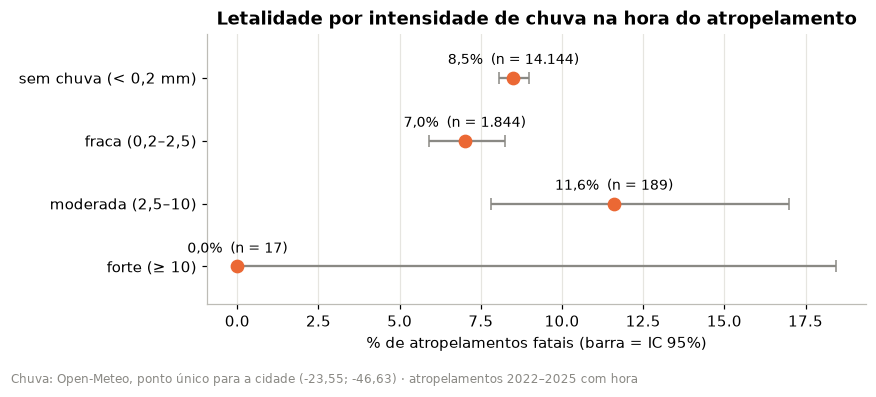

In [4]:
def wilson(f, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = f / n; den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den; m = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (c - m, c + m)

com_hora = atrop[atrop["chuva_mm"].notna()].copy()
com_hora["faixa"] = pd.cut(com_hora["chuva_mm"], [-0.01, 0.199, 2.5, 10, np.inf],
                           labels=["sem chuva (< 0,2 mm)", "fraca (0,2–2,5)", "moderada (2,5–10)", "forte (≥ 10)"])
def tabela(grupo):
    t = com_hora.groupby(grupo, observed=False)["fatal"].agg(atropelamentos="size", fatais="sum")
    t["letalidade_%"] = (t["fatais"] / t["atropelamentos"] * 100).round(1)
    ic = [wilson(f, n) for f, n in zip(t["fatais"], t["atropelamentos"])]
    t["IC95_%"] = [f"{a * 100:.1f}–{b * 100:.1f}" for a, b in ic]
    return t
t_chuva = tabela(com_hora["chovendo"].map({0.0: "sem chuva", 1.0: "chovendo"}))
t_faixa = tabela("faixa")
display(t_chuva); display(t_faixa)

fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(t_faixa))[::-1]
ic = np.array([wilson(f, n) for f, n in zip(t_faixa["fatais"], t_faixa["atropelamentos"])]) * 100
ax.errorbar(t_faixa["letalidade_%"], y, xerr=[t_faixa["letalidade_%"] - ic[:, 0], ic[:, 1] - t_faixa["letalidade_%"]],
            fmt="o", color=LARANJA, ecolor=CINZA, capsize=4, ms=8)
for yi, (v, n) in zip(y, zip(t_faixa["letalidade_%"], t_faixa["atropelamentos"])):
    ax.text(v, yi + 0.22, f"{v:.1f}%".replace(".", ",") + f"  (n = {n:,})".replace(",", "."), ha="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(t_faixa.index); ax.set_ylim(-0.6, len(t_faixa) - 0.3)
ax.set_xlabel("% de atropelamentos fatais (barra = IC 95%)"); ax.grid(axis="y", visible=False)
ax.set_title("Letalidade por intensidade de chuva na hora do atropelamento")
fig.text(0.01, -0.04, "Chuva: Open-Meteo, ponto único para a cidade (-23,55; -46,63) · atropelamentos 2022–2025 com hora",
         fontsize=8, color=CINZA)
fig.tight_layout(); salvar(fig, "05_chuva_letalidade.png"); plt.show()

**Leitura: a chuva não aumenta a letalidade nesta base, e isso é um resultado.**

- Com chuva, 7,4% dos atropelamentos foram fatais (IC 6,3–8,6%). Sem chuva, 8,5% (IC 8,1–9,0%). A diferença é
  pequena e vai no sentido **contrário** ao esperado.
- Por intensidade, a chuva **moderada** chega a 11,6%, mas são só 189 casos e o intervalo (7,8–17,0%) se
  sobrepõe ao dos dias secos. A chuva **forte** tem só 17 atropelamentos em 4 anos, nenhum fatal: não dá para
  concluir nada.
- Duas explicações prováveis: (1) a chuva é **de um ponto só** para a cidade inteira (seção 2), o que dilui o
  efeito local; (2) **exposição**: com chuva há menos pedestres na rua e o trânsito anda mais devagar, o que
  pode compensar a visibilidade pior.

**Consequência para o projeto:** o modo **"chuva"** do nó **não pode ser justificado por "mais mortes na
chuva"** com estes dados. Ele se justifica por outros motivos: alagamento, visibilidade, frenagem mais longa,
e o que a literatura de segurança viária registra. O texto do PDF precisa deixar isso claro.

## 3. Base do modelo e divisão temporal

**Unidade:** o sinistro de atropelamento. **Alvo:** `fatal`.

Saem do modelo os registros **sem hora**, **sem tipo de via** ou **sem coordenada válida**. A `risco()` sempre
recebe local e hora, então esses casos não representam o uso real. E, como mostrou o notebook 02, os registros
sem hora ou sem tipo de via são **100% fatais**: são óbitos que chegam por outra fonte, sem o boletim
completo. Mantê-los ensinaria ao modelo que "dado ausente = morte", um padrão que não existe na rua.

**Divisão temporal:** treino = **2022–2023**, teste = **2024**. Prever o ano seguinte com o que se sabia
antes é o uso real. **2025** é só uma checagem extra: os não fatais de 2025 parecem incompletos (notebook 01),
o que infla a letalidade e torna as métricas de 2025 não comparáveis.

In [5]:
motivos = {"sem hora": atrop["hora"].isna(), "sem tipo de via": atrop["tipo_via"].isna(),
           "sem coordenada válida": ~atrop["coord_valida"]}
saida = pd.DataFrame({k: {"registros": int(m.sum()), "fatais": int(atrop.loc[m, "fatal"].sum())} for k, m in motivos.items()}).T
fora = np.logical_or.reduce(list(motivos.values()))
saida.loc["qualquer motivo"] = [int(fora.sum()), int(atrop.loc[fora, "fatal"].sum())]
display(saida)

base = atrop[~fora].reset_index(drop=True)
treino = base[base["ano_sinistro"].isin([2022, 2023])].reset_index(drop=True)
teste = base[base["ano_sinistro"].eq(2024)].reset_index(drop=True)
extra = base[base["ano_sinistro"].eq(2025)].reset_index(drop=True)
pd.DataFrame({n: {"registros": len(d), "fatais": int(d["fatal"].sum()), "% fatais": round(d["fatal"].mean() * 100, 1)}
              for n, d in [("treino 2022–2023", treino), ("teste 2024", teste), ("checagem 2025", extra)]}).T

,registros,fatais
sem hora,51,51
sem tipo de via,114,114
sem coordenada válida,650,166
qualquer motivo,682,198


,registros,fatais,% fatais
treino 2022–2023,8186.0,544.0,6.6
teste 2024,4301.0,313.0,7.3
checagem 2025,3076.0,351.0,11.4


## 4. Variáveis (só o que se conhece antes do atropelamento)

| Variável | O que é | Observação |
|---|---|---|
| `hora_sin`, `hora_cos` | hora no círculo de 24 h | 23h e 0h ficam vizinhas, o que não acontece com a hora como número |
| `dia_semana`, `fim_de_semana` | segunda = 0 … domingo = 6 | |
| `mes_sin`, `mes_cos` | mês no círculo de 12 meses | sazonalidade (chuvas de verão, férias) |
| `chovendo`, `chuva_mm` | chuva na hora (seção 2) | regional |
| `rodovia_local` | 1 se a maioria dos atropelamentos de treino a até 150 m foi em estrada/rodovia | substitui o `tipo_via` do boletim, que a `risco()` não recebe |
| `em_grupo`, `peso_grupo`, `indice_cet_grupo` | o local está num grupo do DBSCAN? peso e índice CET do grupo | DBSCAN **refeito só com o treino** |
| `let_local`, `n_hist_local` | letalidade histórica e nº de atropelamentos do grupo (ou da célula de ~500 m, se fora de grupo) | **só treino** e suavizada |

**Sem vazamento:**
- Os grupos do notebook 03 foram feitos com 2022–2025 e contêm os fatais do teste. Por isso o DBSCAN é
  **refeito aqui só com 2022–2023** (mesmos `eps = 100 m` e `min_samples = 8` em peso). Pontos do teste entram no
  grupo do treino mais próximo a menos de 100 m, exatamente como a `risco()` faz.
- A letalidade local é **suavizada**: (fatais + 20 × taxa global) / (n + 20). Um local com 1 caso fatal em 1
  não vira "100% de letalidade".
- Nas **linhas de treino**, o próprio registro sai das contagens (*leave-one-out*). Senão, a letalidade do
  local conteria o rótulo da própria linha e o modelo aprenderia a "colar".

In [6]:
tabelas = rv.construir_tabelas(treino[["latitude", "longitude", "fatal", "tipo_via"]], eps_m=rv.EPS_M, min_samples=rv.MIN_SAMPLES)
print(f"DBSCAN só com o treino: {len(tabelas['grupos'])} grupos | taxa global de treino: {tabelas['taxa_global']:.2%}")

def variaveis(d, eh_treino=False):
    return rv.montar_variaveis(d["latitude"], d["longitude"], d["quando"], d["chuva_mm"], tabelas,
                               indices_treino=np.arange(len(d)) if eh_treino else None)
X_tr, X_te, X_ex = variaveis(treino, True), variaveis(teste), variaveis(extra)
y_tr, y_te, y_ex = treino["fatal"].astype(int).to_numpy(), teste["fatal"].astype(int).to_numpy(), extra["fatal"].astype(int).to_numpy()
print(f"X_treino {X_tr.shape} | X_teste {X_te.shape} | X_2025 {X_ex.shape} | variáveis: {rv.VARIAVEIS}")
X_te.describe().T.round(3)

DBSCAN só com o treino: 64 grupos | taxa global de treino: 6.65%


X_treino (8186, 14) | X_teste (4301, 14) | X_2025 (3076, 14) | variáveis: ['hora_sin', 'hora_cos', 'dia_semana', 'fim_de_semana', 'mes_sin', 'mes_cos', 'chovendo', 'chuva_mm', 'rodovia_local', 'em_grupo', 'peso_grupo', 'indice_cet_grupo', 'let_local', 'n_hist_local']


,count,mean,std,min,25%,50%,75%,max
hora_sin,4301.0,-0.207,0.712,-1.000,-0.866,-0.500,0.500,1.000
hora_cos,4301.0,-0.223,0.633,-1.000,-0.866,-0.259,0.259,1.000
dia_semana,4301.0,2.851,1.921,0.000,1.000,3.000,4.000,6.000
fim_de_semana,4301.0,0.239,0.427,0.000,0.000,0.000,0.000,1.000
mes_sin,4301.0,-0.020,0.705,-1.000,-0.866,-0.000,0.500,1.000
mes_cos,4301.0,-0.074,0.705,-1.000,-0.866,-0.000,0.500,1.000
chovendo,4301.0,0.116,0.320,0.000,0.000,0.000,0.000,1.000
chuva_mm,4301.0,0.132,0.670,0.000,0.000,0.000,0.000,16.600
rodovia_local,4301.0,0.011,0.105,0.000,0.000,0.000,0.000,1.000
em_grupo,4301.0,0.046,0.209,0.000,0.000,0.000,0.000,1.000


## 5. Modelos e validação cruzada (dentro do treino)

Três modelos, do mais simples ao mais flexível:

1. **Regressão logística** (linha de base), com variáveis padronizadas;
2. **Árvore de decisão** com profundidade **limitada a 3–5 níveis**, para as regras caberem numa página do PDF;
3. **Random forest**.

**Desbalanceamento:** só ~7% dos casos são fatais. Cada modelo é testado **sem tratamento** e com
`class_weight="balanced"` (a classe fatal passa a pesar ~13 vezes mais). A escolha entre os dois sai da
validação cruzada.

**Validação cruzada:** 5 dobras estratificadas **só no treino**, com a métrica **PR-AUC** (*average precision*).
A PR-AUC mede o quanto o modelo encontra os fatais sem encher a lista de falsos alarmes, e não se deixa
enganar pela maioria não fatal, como acontece com a acurácia e, em parte, com a ROC-AUC. *Ressalva:* a
letalidade *leave-one-out* das linhas de treino usa os rótulos das outras linhas de treino, inclusive as da
dobra de validação, então a validação cruzada pode sair um pouco otimista. Por isso a palavra final é do
**teste de 2024**, que não participa de nada antes.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CW = [None, "balanced"]
modelos = {
    "regressão logística": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                            {"logisticregression__C": [0.01, 0.1, 1, 10], "logisticregression__class_weight": CW}),
    "árvore de decisão": (DecisionTreeClassifier(random_state=SEED),
                          {"max_depth": [3, 4, 5], "min_samples_leaf": [50, 100, 200], "class_weight": CW}),
    "random forest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                      {"max_depth": [6, 10], "min_samples_leaf": [20, 50], "max_features": ["sqrt", 0.5],
                       "class_weight": [None, "balanced_subsample"]}),
}
buscas, linhas = {}, []
for nome, (est, grade) in modelos.items():
    gs = GridSearchCV(est, grade, scoring="average_precision", cv=cv, n_jobs=-1).fit(X_tr, y_tr)
    buscas[nome] = gs
    r = pd.DataFrame(gs.cv_results_)
    col_cw = [c for c in r.columns if c.endswith("class_weight")][0]
    for cw, d in r.groupby(r[col_cw].map(lambda v: "None" if v is None or v is np.ma.masked else str(v))):
        melhor = d.loc[d["mean_test_score"].idxmax()]
        linhas.append({"modelo": nome, "desbalanceamento": "class_weight balanceado" if "balanced" in cw else "sem tratamento",
                       "PR-AUC (CV)": round(melhor["mean_test_score"], 4), "± dp": round(melhor["std_test_score"], 4)})
    print(f"{nome}: melhor = {gs.best_params_} | PR-AUC CV = {gs.best_score_:.4f}")
cv_tab = pd.DataFrame(linhas).set_index(["modelo", "desbalanceamento"])
print(f"\nreferência (modelo que chuta): PR-AUC = proporção de fatais no treino = {y_tr.mean():.4f}")
cv_tab

regressão logística: melhor = {'logisticregression__C': 10, 'logisticregression__class_weight': None} | PR-AUC CV = 0.1837


árvore de decisão: melhor = {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 50} | PR-AUC CV = 0.1349


random forest: melhor = {'class_weight': None, 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 20} | PR-AUC CV = 0.2141

referência (modelo que chuta): PR-AUC = proporção de fatais no treino = 0.0665


PR-AUC (CV)    ± dp
modelo              desbalanceamento                            
regressão logística class_weight balanceado       0.1735  0.0465
                    sem tratamento                0.1837  0.0509
árvore de decisão   class_weight balanceado       0.1306  0.0235
                    sem tratamento                0.1349  0.0201
random forest       class_weight balanceado       0.1976  0.0502
                    sem tratamento                0.2141  0.0605

**Leitura (validação cruzada):**

- Os três modelos ficam **acima do chute** (proporção de fatais no treino = 0,067). A random forest vai mais
  longe (PR-AUC 0,214), seguida da regressão logística (0,184) e da árvore (0,135).
- **Tratar o desbalanceamento com `class_weight` não ajudou**: nos três modelos, a versão sem tratamento teve
  PR-AUC um pouco maior. Faz sentido: a PR-AUC mede a **ordenação** dos casos (quem tem mais risco vem
  primeiro), e repesar as classes muda pouco a ordem. O desbalanceamento é tratado onde realmente importa, no
  **limiar de decisão** (seção 6), que é colocado bem abaixo de 0,5 para pegar 70% dos fatais.
- O desvio entre as dobras é grande (±0,05 a ±0,06), sinal de que o sinal existe, mas é fraco e instável.

## 6. Limiar de decisão e métricas no teste (2024)

**Limiar:** o modelo devolve uma probabilidade, e o "alerta de fatal" dispara acima de um corte. Pedimos
**recall da classe fatal ≥ 0,70** (pegar pelo menos 70% dos atropelamentos que matam). O corte é escolhido nas
**previsões fora da dobra do treino** (*out-of-fold*), como **o maior limiar que ainda dá recall ≥ 0,70**, e
só depois aplicado ao teste. Escolher o limiar olhando o teste seria trapaça. Por isso o recall no teste
pode sair um pouco acima ou abaixo de 0,70.

In [8]:
def limiar_para_recall(y, p, alvo=0.70):
    prec, rec, lim = precision_recall_curve(y, p)
    ok = np.flatnonzero(rec[:-1] >= alvo)
    return float(lim[ok[-1]])

resultados, prob_te, limiares = [], {}, {}
for nome, gs in buscas.items():
    oof = cross_val_predict(gs.best_estimator_, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    limiares[nome] = limiar_para_recall(y_tr, oof)
    p = gs.best_estimator_.predict_proba(X_te)[:, 1]; prob_te[nome] = p
    yhat = (p >= limiares[nome]).astype(int)
    resultados.append({"modelo": nome, "PR-AUC": average_precision_score(y_te, p), "ROC-AUC": roc_auc_score(y_te, p),
                       "limiar": limiares[nome], "recall fatal": recall_score(y_te, yhat),
                       "precisão fatal": precision_score(y_te, yhat, zero_division=0),
                       "alertas (% dos casos)": yhat.mean() * 100,
                       "PR-AUC ÷ proporção de fatais": average_precision_score(y_te, p) / y_te.mean()})
res = pd.DataFrame(resultados).set_index("modelo").round(4)
print(f"teste 2024: {len(y_te):,} atropelamentos, {y_te.sum()} fatais → proporção (PR-AUC de quem chuta) = {y_te.mean():.4f}")
res

teste 2024: 4,301 atropelamentos, 313 fatais → proporção (PR-AUC de quem chuta) = 0.0728


,PR-AUC,ROC-AUC,limiar,recall fatal,precisão fatal,alertas (% dos casos),PR-AUC ÷ proporção de fatais
modelo,,,,,,,
regressão logística,0.1514,0.6209,0.0544,0.6550,0.0979,48.6864,2.0804
árvore de decisão,0.1216,0.6063,0.0441,0.8754,0.0749,85.0267,1.6711
random forest,0.1615,0.6247,0.0528,0.6358,0.0986,46.9193,2.2196


**Leitura (teste 2024, que o modelo nunca viu):**

- **PR-AUC:** random forest 0,162, regressão logística 0,151, árvore 0,122. A referência de quem chuta é a
  proporção de fatais em 2024, **0,073**. A random forest fica **2,2 vezes acima do chute**, mas o valor
  absoluto é baixo. A **ROC-AUC de 0,62 a 0,63** é fraca: o notebook 02, que conhece a idade da vítima,
  chegava a 0,77.
- **Limiar para recall ≥ 0,70:** o limiar escolhido no treino dá, no teste, **recall de 0,64** (199 de 313
  fatais) e **precisão de 0,099**. Ou seja, **para pegar ~2/3 dos atropelamentos fatais, o modelo alerta em
  47% de todos os casos**, e só 1 em cada 10 alertas é de fato fatal. Isso é pouco melhor que os 7,3% de
  quem chuta. **É o custo de exigir recall alto com um sinal fraco.**
- Ficar um pouco abaixo de 0,70 no teste é o preço de não escolher o limiar olhando o teste. 2024 tem um
  pouco mais de fatais que o treino.

### 6.1 Escolha do modelo final

**Regra fixada antes de olhar o teste:** fica o modelo com a **maior PR-AUC na validação cruzada do treino**.
A tabela do teste serve para confirmar que a escolha se sustenta fora do treino, não para escolher.

In [9]:
FINAL = max(buscas, key=lambda n: buscas[n].best_score_)
modelo = buscas[FINAL].best_estimator_
LIMIAR = limiares[FINAL]
p_te = prob_te[FINAL]
print(f"modelo final: {FINAL} | parâmetros: {buscas[FINAL].best_params_} | limiar: {LIMIAR:.4f}")

modelo final: random forest | parâmetros: {'class_weight': None, 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 20} | limiar: 0.0528


**Escolha: random forest** (sem `class_weight`, profundidade máxima 10, ≥ 20 casos por folha, `max_features =
sqrt`), pela regra fixada antes de ver o teste: maior PR-AUC na validação cruzada. O teste confirma a ordem (é
também a melhor no teste), mas a vantagem sobre a regressão logística é pequena (0,162 × 0,151). A **árvore de
decisão** não é o modelo final, mas fica no PDF pelas **regras legíveis** (seção 7).

### 6.2 Curva precisão × recall e matriz de confusão

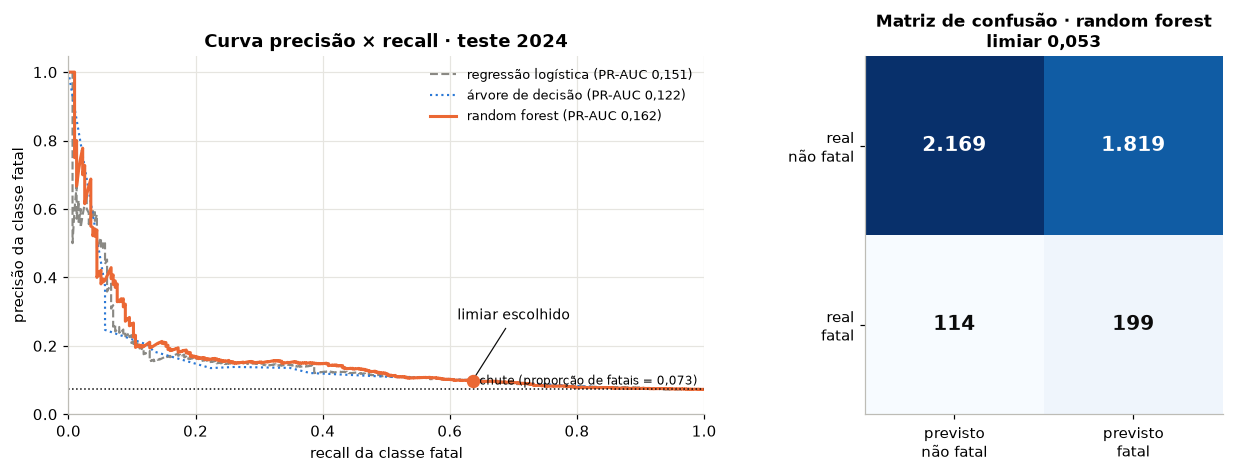

fatais encontrados: 199 de 313 (recall 0.64) | alertas: 2,018, dos quais 199 fatais (precisão 0.099)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
estilo = {"regressão logística": (CINZA, "--"), "árvore de decisão": (AZUL, ":"), "random forest": (AZUL, "-")}
for nome, p in prob_te.items():
    prec, rec, _ = precision_recall_curve(y_te, p)
    cor, ls = estilo[nome]
    if nome == FINAL:
        cor = LARANJA
    ax.plot(rec, prec, color=cor, ls=ls, lw=2 if nome == FINAL else 1.4,
            label=f"{nome} (PR-AUC {average_precision_score(y_te, p):.3f})".replace(".", ","))
ax.axhline(y_te.mean(), color="#0b0b0b", lw=1, ls=":")
ax.text(0.99, y_te.mean() + 0.005, f"chute (proporção de fatais = {y_te.mean():.3f})".replace(".", ","), ha="right",
        va="bottom", fontsize=8)
yhat = (p_te >= LIMIAR).astype(int)
ax.scatter([recall_score(y_te, yhat)], [precision_score(y_te, yhat)], color=LARANJA, zorder=5, s=60)
ax.annotate("limiar escolhido", (recall_score(y_te, yhat), precision_score(y_te, yhat)), xytext=(-10, 40),
            arrowprops=dict(arrowstyle="-", color="#0b0b0b", lw=0.8),
            textcoords="offset points", fontsize=9)
ax.set_xlabel("recall da classe fatal"); ax.set_ylabel("precisão da classe fatal")
ax.set_title("Curva precisão × recall · teste 2024"); ax.legend(frameon=False, fontsize=8.5)
ax.set_xlim(0, 1); ax.set_ylim(0, max(0.5, ax.get_ylim()[1]))

ax = axes[1]
cm = confusion_matrix(y_te, yhat)
ax.imshow(cm, cmap="Blues"); ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}".replace(",", "."), ha="center", va="center", fontsize=13,
            color="white" if v > cm.max() / 2 else "#0b0b0b", fontweight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["previsto\nnão fatal", "previsto\nfatal"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["real\nnão fatal", "real\nfatal"])
ax.set_title(f"Matriz de confusão · {FINAL}\nlimiar {LIMIAR:.3f}".replace(".", ","), fontsize=11)
fig.tight_layout(); salvar(fig, "05_curva_pr_matriz_confusao.png"); plt.show()
print(f"fatais encontrados: {cm[1, 1]} de {cm[1].sum()} (recall {cm[1, 1] / cm[1].sum():.2f}) | "
      f"alertas: {cm[:, 1].sum():,}, dos quais {cm[1, 1]} fatais (precisão {cm[1, 1] / cm[:, 1].sum():.3f})")

### 6.3 Checagem extra: 2025 (com ressalva)

Os não fatais de 2025 parecem incompletos (notebook 01), então a proporção de fatais está inflada. A PR-AUC
depende dessa proporção, por isso comparamos a **razão PR-AUC ÷ proporção** e a **ROC-AUC**, que não
dependem dela. Serve só para ver se o modelo não desmorona num ano novo.

In [11]:
p_ex = modelo.predict_proba(X_ex)[:, 1]
pd.DataFrame({"teste 2024": {"proporção de fatais": y_te.mean(), "PR-AUC": average_precision_score(y_te, p_te),
                             "PR-AUC ÷ proporção": average_precision_score(y_te, p_te) / y_te.mean(), "ROC-AUC": roc_auc_score(y_te, p_te)},
              "checagem 2025": {"proporção de fatais": y_ex.mean(), "PR-AUC": average_precision_score(y_ex, p_ex),
                                "PR-AUC ÷ proporção": average_precision_score(y_ex, p_ex) / y_ex.mean(), "ROC-AUC": roc_auc_score(y_ex, p_ex)}}).round(3)

,teste 2024,checagem 2025
proporção de fatais,0.073,0.114
PR-AUC,0.162,0.203
PR-AUC ÷ proporção,2.220,1.776
ROC-AUC,0.625,0.632


## 7. O que o modelo usa

**Importância por permutação, no teste:** embaralhamos uma variável de cada vez e medimos quanto a PR-AUC cai.
Uma queda grande significa que o modelo depende dela. É medida no **teste**, então mostra o que generaliza, e
não o que o modelo decorou.

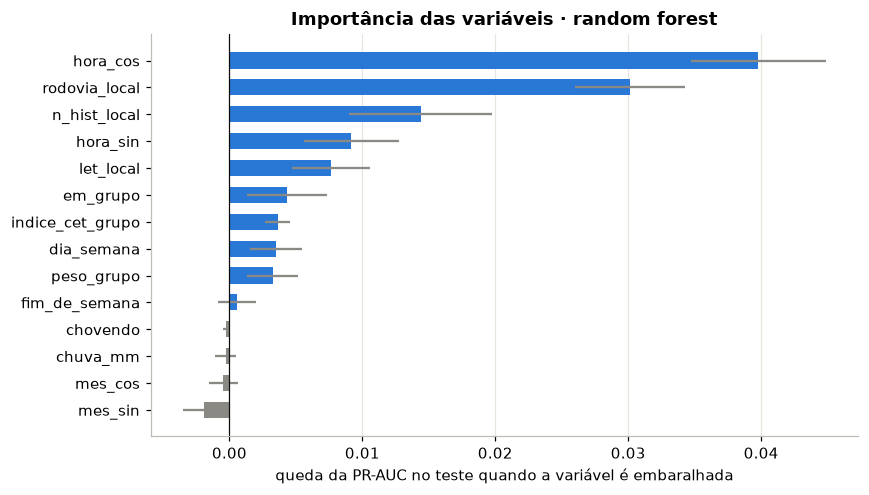

,queda média da PR-AUC,dp
hora_cos,0.0398,0.0051
rodovia_local,0.0301,0.0041
n_hist_local,0.0144,0.0054
hora_sin,0.0092,0.0035
let_local,0.0077,0.0029
em_grupo,0.0043,0.0030
indice_cet_grupo,0.0036,0.0009
dia_semana,0.0035,0.0020
peso_grupo,0.0033,0.0019
fim_de_semana,0.0006,0.0014


In [12]:
imp = permutation_importance(modelo, X_te, y_te, scoring="average_precision", n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"queda média da PR-AUC": imp.importances_mean, "dp": imp.importances_std}, index=rv.VARIAVEIS
                   ).sort_values("queda média da PR-AUC", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.6))
t = imp.iloc[::-1]
ax.barh(t.index, t["queda média da PR-AUC"], xerr=t["dp"], color=np.where(t["queda média da PR-AUC"] > 0, AZUL, CINZA),
        ecolor=CINZA, height=0.6)
ax.axvline(0, color="#0b0b0b", lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("queda da PR-AUC no teste quando a variável é embaralhada")
ax.set_title(f"Importância das variáveis · {FINAL}")
fig.tight_layout(); salvar(fig, "05_importancia_variaveis.png"); plt.show()
imp.round(4)

**Regras da árvore de decisão** (o modelo legível, para o PDF). Cada folha mostra `weights: [não fatais,
fatais]` no treino. Todas as folhas "votam" não fatal, porque em nenhuma os fatais são maioria; a
informação está na **proporção** de fatais em cada folha. Para
ler a hora: `hora_cos` alto (perto de 1) = **madrugada** (0h–3h); `hora_cos` baixo (perto de −1) = **meio-dia**;
`hora_sin` negativo = **tarde e noite** (13h–23h).

In [13]:
arvore = buscas["árvore de decisão"].best_estimator_
regras = export_text(arvore, feature_names=rv.VARIAVEIS, show_weights=True, decimals=3)
(EVID / "05_regras_arvore.txt").write_text(
    f"Árvore de decisão (fatal × não fatal), parâmetros {buscas['árvore de decisão'].best_params_}\n"
    f"Treino 2022–2023; em cada folha, 'weights: [não fatais, fatais]' no treino.\n\n{regras}", encoding="utf-8")
print(regras)

|--- rodovia_local <= 0.500
|   |--- hora_cos <= 0.129
|   |   |--- peso_grupo <= 2.000
|   |   |   |--- dia_semana <= 5.500
|   |   |   |   |--- let_local <= 0.072
|   |   |   |   |   |--- weights: [3635.000, 172.000] class: 0
|   |   |   |   |--- let_local >  0.072
|   |   |   |   |   |--- weights: [892.000, 25.000] class: 0
|   |   |   |--- dia_semana >  5.500
|   |   |   |   |--- hora_sin <= 0.604
|   |   |   |   |   |--- weights: [331.000, 21.000] class: 0
|   |   |   |   |--- hora_sin >  0.604
|   |   |   |   |   |--- weights: [77.000, 12.000] class: 0
|   |   |--- peso_grupo >  2.000
|   |   |   |--- n_hist_local <= 5.500
|   |   |   |   |--- weights: [59.000, 23.000] class: 0
|   |   |   |--- n_hist_local >  5.500
|   |   |   |   |--- indice_cet_grupo <= 23.008
|   |   |   |   |   |--- weights: [276.000, 7.000] class: 0
|   |   |   |   |--- indice_cet_grupo >  23.008
|   |   |   |   |   |--- weights: [44.000, 6.000] class: 0
|   |--- hora_cos >  0.129
|   |   |--- hora_sin <= 0

**Leitura (o que pesa):**

- As **3 variáveis mais importantes** são **`hora_cos`** (madrugada × dia), **`rodovia_local`** e
  **`n_hist_local`** (quantos atropelamentos o local já teve). Depois vêm `hora_sin` e a letalidade histórica
  do local.
- **Chuva e mês têm importância zero ou negativa:** embaralhar essas variáveis não piora o modelo. Isso
  confirma a seção 2.1.
- As **regras da árvore** contam a mesma história em linguagem simples:
  - **em rodovia**, 34 de 88 atropelamentos de treino foram fatais (**39%**);
  - **de madrugada (1h–5h)**, em local com letalidade histórica acima de ~5%: **27%** fatais (50 de 186);
  - **à noite (19h–0h)**, em local com letalidade histórica alta e pouco movimento registrado: **13%** (70 de 535);
  - **de dia (6h–18h)**, fora dos grupos: **4,5%** (172 de 3.807).

Para o PDF: o risco de **morte** é sobretudo uma questão de **horário e tipo de via** (velocidade), enquanto
o risco de **atropelamento** se concentra nos pontos do DBSCAN (volume). Os dois se complementam.

## 8. Níveis de risco e exportação do modelo

A `risco()` devolve, além da probabilidade, um **nível** para a placa e para a central. Os cortes vêm dos
**quantis das probabilidades previstas no teste 2024**:

- **baixo**: abaixo da mediana (metade dos casos com menor probabilidade);
- **médio**: entre a mediana e o percentil 90;
- **alto**: os **10%** com maior probabilidade.

A tabela abaixo mostra que o nível tem sentido: a proporção real de fatais deve subir de um nível para o outro.

In [14]:
CORTES = {"medio": float(np.quantile(p_te, 0.50)), "alto": float(np.quantile(p_te, 0.90))}
nivel_te = np.where(p_te >= CORTES["alto"], "alto", np.where(p_te >= CORTES["medio"], "medio", "baixo"))
niveis = (pd.DataFrame({"nivel": nivel_te, "fatal": y_te}).groupby("nivel")["fatal"]
            .agg(casos="size", fatais="sum").reindex(["baixo", "medio", "alto"]))
niveis["% fatais (real)"] = (niveis["fatais"] / niveis["casos"] * 100).round(1)
niveis["% dos fatais do ano"] = (niveis["fatais"] / niveis["fatais"].sum() * 100).round(1)
print(f"cortes: médio ≥ {CORTES['medio']:.4f} | alto ≥ {CORTES['alto']:.4f}")
niveis

cortes: médio ≥ 0.0509 | alto ≥ 0.1113


,casos,fatais,% fatais (real),% dos fatais do ano
nivel,,,,
baixo,2150,106,4.9,33.9
medio,1720,138,8.0,44.1
alto,431,69,16.0,22.0


In [15]:
# Tabela oficial dos grupos (notebook 03, 2022–2025) — só para informar cluster_id e rank na resposta da risco()
with sqlite3.connect(DB_PATH) as con:
    pts_oficiais = pd.read_sql_query("SELECT latitude, longitude, cluster_id FROM sinistros WHERE cluster_id IS NOT NULL", con)
    grupos_oficiais = pd.read_sql_query("SELECT cluster_id, rank_prioridade, rank_urbano, via_principal FROM clusters", con)

pacote = {
    "modelo": modelo, "nome_modelo": FINAL, "parametros": buscas[FINAL].best_params_, "variaveis": rv.VARIAVEIS,
    "tabelas": tabelas, "limiar_recall_70": LIMIAR, "cortes_nivel": CORTES,
    "oficial_arvore": BallTree(np.radians(pts_oficiais[["latitude", "longitude"]].to_numpy()), metric="haversine"),
    "oficial_rotulos": pts_oficiais["cluster_id"].astype(int).to_numpy(),
    "oficial_grupos": grupos_oficiais.set_index("cluster_id").to_dict("index"),
    "metricas_teste_2024": res.loc[FINAL].to_dict(),
    "treino": "2022–2023", "teste": "2024", "criado_em": dt.datetime.now().isoformat(timespec="seconds"),
}
ARQ_MODELO = MODELS / "modelo_gravidade.joblib"
joblib.dump(pacote, ARQ_MODELO, compress=3)
print(f"salvo: {ARQ_MODELO.relative_to(ROOT)} ({ARQ_MODELO.stat().st_size / 1e6:.1f} MB)")

salvo: models\modelo_gravidade.joblib (1.5 MB)


## 9. A função `risco()` em uso

A função fica em `src/estudo_b_risco_vida/risco.py` e carrega o pacote acima **uma vez só** (cache). Os testes
automáticos estão em `tests/test_risco.py` (rodar `python -m pytest tests -v` a partir de
``). Abaixo, alguns cenários para o piloto:

In [16]:
import importlib; importlib.reload(rv)
LARGO = (-23.54231, -46.61655)
cenarios = [("terça 18h30, sem chuva", dt.datetime(2026, 11, 10, 18, 30), 0.0),
            ("terça 18h30, chuva forte", dt.datetime(2026, 11, 10, 18, 30), 15.0),
            ("sábado 03h, sem chuva", dt.datetime(2026, 11, 14, 3, 0), 0.0),
            ("sábado 03h, chuva 10 mm", dt.datetime(2026, 11, 14, 3, 0), 10.0)]
pd.DataFrame([{"cenário (Largo da Concórdia)": n, **{k: v for k, v in rv.risco(*LARGO, q, c).items()}} for n, q, c in cenarios])

,cenário (Largo da Concórdia),probabilidade_fatal,nivel,cluster_id,rank_prioridade,rank_urbano,motivos
0,"terça 18h30, sem chuva",0.0457,baixo,139,41,26,[ponto crítico (DBSCAN)]
1,"terça 18h30, chuva forte",0.0645,medio,139,41,26,"[chuva, ponto crítico (DBSCAN)]"
2,"sábado 03h, sem chuva",0.0604,medio,139,41,26,"[madrugada, fim de semana, ponto crítico (DBSC..."
3,"sábado 03h, chuva 10 mm",0.0748,medio,139,41,26,"[madrugada, chuva, fim de semana, ponto crític..."


**Leitura (cenários no Largo da Concórdia):** a probabilidade sobe de 4,6% (terça 18h30, seco) para 7,5%
(sábado 3h, com chuva). Os **níveis** usam cortes do teste (médio ≥ 5,1%, alto ≥ 11,1%), e no teste a
proporção real de fatais sobe de nível para nível: **4,9% → 8,0% → 16,0%**. O nível tem sentido como
**ordenação**.

*Cuidado com a chuva:* nos cenários, a chuva aumenta a probabilidade (de 4,6% para 6,5% às 18h30), mas a
importância por permutação da chuva é **zero** (seção 7). Esse aumento é ruído das interações internas da
random forest, **não um efeito demonstrado**. A central não deve apresentar "chuva aumenta o risco de morte"
como conclusão dos dados.

## 10. Plano B e limitações

**Avaliação honesta: o classificador é fraco como detector de atropelamento fatal, e o plano B se aplica.**

- PR-AUC de 0,162 contra 0,073 de quem chuta, e ROC-AUC de 0,625. O modelo **ordena** os casos melhor que o
  acaso (o nível "alto" tem 3,3 vezes mais fatais que o "baixo"), mas **não separa** fatais de não fatais: no
  limiar de recall 0,64, 9 em cada 10 alertas são falsos.
- O motivo principal é estrutural: a `risco()` **não pode saber quem será atropelado**, e a idade da vítima é o
  fator mais forte para a morte (notebook 02).

**Plano B aplicado:**
1. **Onde agir** (escolha e prioridade dos pontos, inclusive o piloto) continua decidido pelo **índice do
   DBSCAN** (`rank_prioridade` / `rank_urbano`, notebooks 03 e 04). O classificador não muda nenhuma
   prioridade.
2. A `risco()` entra só como **modulador de "quando"** dentro de um ponto já priorizado, para a central
   escolher o modo do nó (por exemplo, reforçar o modo "pedestre" de madrugada). Ela devolve o `cluster_id`
   e o `rank_prioridade`, e é com eles que a central decide.
3. O efeito da **chuva** **não** é usado como argumento de letalidade (seção 2.1).

No PDF, o modelo aparece como **resultado negativo bem documentado**: o que foi testado, por que não serve
como classificador e o que se usa no lugar.

**Limitações**
- **Chuva regional:** um ponto só do Open-Meteo para a cidade inteira. Chuva localizada não aparece.
- **Sem variáveis da vítima, de propósito.** O notebook 02 mostra que idade é o fator mais forte para a morte.
  Um modelo que não sabe quem vai ser atropelado tem um teto baixo de desempenho, e isso explica boa parte da
  PR-AUC modesta.
- **Exposição desconhecida:** não sabemos quantos pedestres e carros passam em cada hora. A "madrugada
  perigosa" mistura velocidade maior com poucas pessoas na rua.
- **Registros excluídos** (sem hora, sem tipo de via ou sem coordenada, seção 3) são sobretudo óbitos. O modelo
  vale para atropelamentos registrados com boletim completo.
- **Grupos do treino ≠ grupos oficiais:** as variáveis do local vêm do DBSCAN de 2022–2023, para não vazar o
  teste. O `cluster_id` e o `rank_prioridade` que a `risco()` informa vêm do ranking oficial (2022–2025,
  notebook 03).
- **2025 incompleto:** serve só como checagem; as métricas oficiais são as do teste 2024.